# Document Processing and Knowledge Base

This notebook processes GitHub project files (text and images) using OpenRouter LLM models. 
It extracts summaries, generates embeddings, creates a ChromaDB knowledge base, and visualizes 
semantic relationships using PCA and UMAP dimensionality reduction.

### Main goals

- extract and process documents (text and images) from GitHub repositories
- generate LLM-powered summaries and structured chunks optimized for semantic retrieval
- build ChromaDB knowledge base with semantic embeddings for fast search
- visualize document relationships using PCA (2D) and UMAP (2D/3D) projections

In [1]:
import os
import json
import subprocess
import umap
import numpy as np
import pandas as pd
import plotly.express as px
from pathlib import Path
from config.settings import EXPORT_DIR, DATA_DIR, RESULTS_FIG

from tqdm import tqdm
from openai import OpenAI
from dotenv import load_dotenv
from pydantic import BaseModel, Field
from collections import defaultdict
from chromadb import PersistentClient
from sklearn.decomposition import PCA

---
## Model Selection and Parameters

In [2]:
# Load environment variables
load_dotenv(override=True)

# GitHub projects to process
projects = {
    'project1': 'https://github.com/thomas819-coder/market-event-impact',
    'project2': 'https://github.com/thomas819-coder/energy-grid-demand-forecasting',
    'project3': 'https://github.com/thomas819-coder/supply-anomaly-classification',
    # 'project4': ''
}

# Initialize OpenAI client with OpenRouter API
client = OpenAI(
    api_key=os.getenv('OPENROUTER_API_KEY'),
    base_url='https://openrouter.ai/api/v1',
)

# Model selection
VISION_MODEL = 'openai/gpt-4o-mini'               # 128k context; .15/M input; .6/M output
TEXT_MODEL = 'anthropic/claude-sonnet-5.5'        # 1M context; 2/M input; 10/M output
EMBEDDING_MODEL = 'openai/text-embedding-3-small' # 8k context; .02/M input

# Processing parameters
AVERAGE_CHUNK_SIZE = 1e3
MAX_TEXT_TOKENS = 200e3
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.gif', '.webp', '.bmp', '.tiff'}
EXCLUDED_EXTENSIONS = ('.pkl', '.ckpt', '.parquet', '.html')
EXCLUDED_FILENAMES = {'.gitignore', '.gitkeep', '__init__.py'}

export_dir = Path(EXPORT_DIR)
data_dir = Path(DATA_DIR)
results_fig = Path(RESULTS_FIG)
results_fig.mkdir(parents=True, exist_ok=True)

---
## Pydantic Models

In [ ]:
# Model for processed document with metadata
class ProcessedDocument(BaseModel):
    project: str
    source: str
    type: str
    text: str

---
## Custom Functions
### 1. Prompt Generation

In [ ]:
def make_image_prompt(project, source):
    """
    Create a detailed prompt for image analysis using Vision model.
    """
    return f"""
Analyze this image in detail and create rich metadata for search and retrieval.
Project: {project}
Source: {source}

Return the following:
1. Image type
2. Visible objects/components
3. Chart/diagram structure if present
4. Text visible in the image
5. Key values, labels, axes, legends
6. What the image is about
7. Likely purpose in the project
8. Useful keywords for retrieval

Be precise and detailed.
"""


def make_text_prompt(project, source, text):
    """
    Create a prompt for text document processing. Split text into structured chunks suitable for retrieval.
    """
    how_many = max(1, (len(text) // AVERAGE_CHUNK_SIZE) + 1)

    return f"""
You are processing a document for a knowledge base.
Project: {project}
Source: {source}

Split the document into overlapping chunks suitable for retrieval.
The document should probably be split into about {how_many} chunks, but adjust as needed.
Rules:
- Preserve all important information
- Include overlap between chunks
- Do not omit any content
- Each chunk should contain:
  - headline
  - summary
  - text

Return only structured JSON.
Here is the document:
{text}
"""

### 2. Document processing

In [ ]:
def process_image_document(project, source, image_url):
    """
    Process an image document using Vision model. Send image with prompt and return processed document.
    """
    prompt = make_image_prompt(project, source)

    response = client.chat.completions.create(
        model=VISION_MODEL,
        messages=[
            {'role': 'user',
             'content': [
                 {'type': 'text', 'text': prompt},
                 {'type': 'image_url', 'image_url': {'url': image_url}}
            ]}],
        temperature=0.2
    )

    reply = response.choices[0].message.content

    return ProcessedDocument(
        project=project,
        source=source,
        type='image',
        text=reply
    )


def process_text_document(project, source, text_parts):
    """
    Process a text document. If document is large, split into parts and process each separately.
    Return list of processed document chunks.
    """
    processed = []

    for part in text_parts:
        prompt = make_text_prompt(
            project=project,
            source=source,
            text=part
        )

        response = client.chat.completions.create(
            model=TEXT_MODEL,
            messages=[
                {'role': 'user',
                 'content': prompt}
                ],
            temperature=0.2
        )

        reply = response.choices[0].message.content

        doc = ProcessedDocument(
            project=project,
            source=source,
            type='text',
            text=reply
        )
        processed.append(doc)

    return processed

### 3. Text Splitting

In [3]:
def split_large_text(text, max_tokens=MAX_TEXT_TOKENS, overlap_chars=1000):
    """
    Split large text into smaller parts if it exceeds max_tokens. Parts overlap for context preservation.
    """
    # Heuristic: 1 token ≈ 3.5 characters
    if (len(text) // 3.5) <= max_tokens:
        return [text]

    max_chars = int(max_tokens * 3.5)
    chunks = []
    start = 0

    while start < len(text):
        end = min(start + max_chars, len(text))

        # If at end of text, append remainder
        if end >= len(text):
            chunks.append(text[start:])
            break

        # Find the optimal split point (end of sentence or word)
        split_point = text.rfind('\n', start, end)

        # If no newline exists, attempt to split at a space
        if split_point == -1 or split_point <= start:
            split_point = text.rfind(' ', start, end)

        # If that also fails, split at the end of the interval
        if split_point == -1 or split_point <= start:
            split_point = end

        chunks.append(text[start:split_point])

        # Continue with overlap
        start = split_point - overlap_chars
        if start < 0:
            start = split_point

    return chunks


def unwrap_json_text(raw):
    """
    Removes markdown wrapper of type ```json ... ``` and attempts to parse the text as JSON.
    If parsing fails, returns None.
    """
    if not raw:
        return None
    s = raw.strip()

    # Remove the beginning ```json or ```
    if s.startswith("```json"):
        s = s[7:].strip()
    elif s.startswith("```"):
        s = s[3:].strip()

    # Remove the ending ``` 
    if s.endswith("```"):
        s = s[:-3].strip()

    # Parse JSON
    try:
        return json.loads(s)
    except:
        return None

---
## Load Projects from GitHub

In [ ]:
print(f'Loading projects from GitHub...')
all_projects = {}

for project_num, project_url in projects.items():
    print(f"\n{'='*60}")
    print(f"Loading {project_url.split('/')[-1]} ({project_num})")

    # Clone or pull repository
    subprocess.run(['git', 'clone', project_url, project_num], capture_output=True)

    project_dict = {}

    # Iterate through all project files
    for root, dirs, files in os.walk(project_num):
        for file in files:
            # Exclude .git folder and specific file types and extensions
            if '.git' in root or file in EXCLUDED_FILENAMES or file.endswith(EXCLUDED_EXTENSIONS):
                continue

            filepath = Path(root) / file
            relative_path = Path(filepath).relative_to(Path(project_num))
            relative_path_str = str(relative_path.as_posix())

            file_ext = Path(filepath).suffix.lower()
            is_image = file_ext in IMAGE_EXTENSIONS

            try:
                if is_image:
                    # Generate raw GitHub URL
                    repo_path = project_url.replace('https://github.com/', '')
                    raw_url = f'https://raw.githubusercontent.com/{repo_path}/refs/heads/main/{relative_path.as_posix()}'
                    project_dict[relative_path_str] = raw_url
                else:
                    # Read file contents
                    with open(filepath, 'r', encoding='utf-8', errors='ignore') as f:
                        project_dict[relative_path_str] = f.read()

            except Exception as e:
                print(f'✗ Error in {relative_path}\n{e}')

    # Store in a global variable
    globals()[project_num] = project_dict
    all_projects[project_num] = project_dict

    print(f'{len(project_dict)} files loaded')

---
## Process All Documents Using LLM Models

In [ ]:
processed_documents = []

for project_num, project_dict in all_projects.items():
    print(f"\n{'='*60}")
    print(f'Processing {project_num}')

    project_url = projects[project_num]

    for path, content in tqdm(project_dict.items(), desc=project_num):
        ext = Path(path).suffix.lower()
        is_image = ext in IMAGE_EXTENSIONS

        try:
            if is_image:
                doc = process_image_document(
                    project=project_num,
                    source=path,
                    image_url=content
                )
                processed_documents.append(doc)

            else:
                text = content
                text_parts = split_large_text(text, max_tokens=MAX_TEXT_TOKENS, overlap_chars=1000)

                docs = process_text_document(
                    project=project_num,
                    source=path,
                    text_parts=text_parts
                )
                
                processed_documents.extend(docs)

        except Exception as e:
            print(f'✗ Error in {project_num} - {path}\n{e}')

## Save Processed Documents to JSON

In [ ]:
# Save processed documents for future use
documents_to_save = [doc.model_dump() for doc in processed_documents]

with open(export_dir / 'processed_documents.json', 'w', encoding='utf-8') as f:
    json.dump(documents_to_save, f, ensure_ascii=False, indent=2)

print(f'processed_documents.json saved')

---
# Transform raw JSON into a flattened structure for ChromaDB

In [4]:
# Check if data exists
if 'documents_to_save' in globals():
    print('✓ Using newly processed data from LLM models')
    
elif 'data' in globals():
    print('✓ Data loaded from processed_documents.json')

else:
    print('⬇️ Loading data from processed_documents.json')
    with open(export_dir / 'processed_documents.json', 'r', encoding='utf-8') as f:
        data = json.load(f)

⬇️ Loading data from processed_documents.json


In [5]:
# Group documents by (project, source, type)
grouped = defaultdict(list)

for item in data:
     # Extract and process text from "text" field for text
    parsed = unwrap_json_text(item.get('text', ''))

    # If parsed is a dict and contains "chunks", use them
    if isinstance(parsed, dict) and 'chunks' in parsed:
        chunks = parsed['chunks']
    # If parsed is a list, use it directly as chunks
    elif isinstance(parsed, list):
        chunks = parsed
    # Extract and process text from "text" field for images
    elif item.get('type') == 'image':
        raw_text = item.get('text', '')
        
        head_start = raw_text.find('Image Type') + 14
        head_stop = raw_text.find('Visible Objects/Components') - 7
        summary_start = raw_text.find('What the Image is About') + 32
        chunks = [{
            'headline': raw_text[head_start:head_stop],
            'summary': raw_text[summary_start:],
            'text': raw_text
        }]
    # If text is not valid JSON, skip the document
    else:
        continue

    # Create document key and add its chunks to the group
    key = (item['project'], item['source'], item['type'])
    grouped[key].extend(chunks)

In [6]:
# Flatten to single list
flat = []
seen_chunks = set()

# Iterate through all document groups
for (project, source, doc_type), chunks in grouped.items():
    for i, c in enumerate(chunks):
        # Chunk must be a dictionary
        if not isinstance(c, dict):
            continue

        # Create a unique chunk identifier based on content
        chunk_key = (
            project,
            source,
            c.get('headline', ''),
            c.get('summary', ''),
            c.get('text', '')
        )

        # If this chunk already exists, skip it
        if chunk_key in seen_chunks:
            continue

        # Add the processed chunk to the set
        seen_chunks.add(chunk_key)

        flat.append({
            'project': project,
            'source': source,
            'type': doc_type,
            'chunk_id': i,
            'headline': c.get('headline', ''),
            'summary': c.get('summary', ''),
            'text': c.get('text', '')
        })

# Save the result to a JSON file
with open(data_dir / 'processed_documents_flattened.json', 'w', encoding='utf-8') as f:
    json.dump(flat, f, ensure_ascii=False, indent=2)

print(f'processed_documents_flattened.json saved')
print(f"Flattened chunks: {len(flat)}")

processed_documents_flattened.json saved
Flattened chunks: 436


---
## Create ChromaDB Knowledge Base

In [7]:
collection_name = 'knowledge_base'

# Only SUMMARIES go to embedding model
summaries = [chunk.get('summary', '') for chunk in flat]

In [8]:
# Initialize ChromaDB client
response = client.embeddings.create(
    model=EMBEDDING_MODEL,
    input=summaries
)

embeddings = [item.embedding for item in response.data]

print(f'Embeddings count: {len(embeddings)}')
print(f'Embedding dimensionality: {len(embeddings[0])}')

Embeddings count: 436
Embedding dimensionality: 1536


In [9]:
# Setup ChromaDB
chroma = PersistentClient(path=str(data_dir / 'chroma_db'))

# If collection already exists, delete it
existing_collections = [c.name for c in chroma.list_collections()]
if collection_name in existing_collections:
    chroma.delete_collection(collection_name)

collection = chroma.get_or_create_collection(
    name=collection_name,
    metadata={'hnsw:space': 'cosine'}
)

# Prepare data for ChromaDB storage
ids = [str(i) for i in range(len(flat))]
documents = summaries
metadatas = []

for chunk in flat:
    meta = {
        'project': chunk.get('project', ''),
        'source': chunk.get('source', ''),
        'type': chunk.get('type', ''),
        'chunk_id': str(chunk.get('chunk_id', '')),
        'headline': chunk.get('headline', ''),
        'text': chunk.get('text', '')
    }

    metadatas.append(meta)

collection.add(
    ids=ids,
    embeddings=embeddings,
    documents=documents,
    metadatas=metadatas
)

print(f'ChromaDB collection created: {collection_name}')

ChromaDB collection created: knowledge_base


---
# Visualize document relationships

In [10]:
# Check if data exists
if 'collection' in globals():
    print('✓ Data loaded from ChromaDB collection')

else:
    print('⬇️ Loading data from ChromaDB collection')
    chroma = PersistentClient(path=str(data_dir / 'chroma_db'))
    collection = chroma.get_or_create_collection(
        name='knowledge_base',
        metadata={'hnsw:space': 'cosine'}
    )

# Load data from ChromaDB collection
result = collection.get(include=['embeddings', 'documents', 'metadatas'])

vectors = np.array(result['embeddings'])
documents = result['documents']
metadatas = result['metadatas']

# Extract information from metadata
doc_types = [meta.get('type', '') for meta in metadatas]
projects = [meta.get('project', '') for meta in metadatas]
sources = [meta.get('source', '') for meta in metadatas]
headlines = [meta.get('headline', '')[:80] for meta in metadatas]

print(f'Statistics:')
print(f'      Embeddings: {len(vectors)}')
print(f'      Dimensions: {vectors.shape[1]}')
print(f'      Projects: {sorted(set(projects))}')
print(f'      Types: {sorted(set(doc_types))}')

✓ Data loaded from ChromaDB collection
Statistics:
      Embeddings: 436
      Dimensions: 1536
      Projects: ['project1', 'project2', 'project3']
      Types: ['image', 'text']


### Visualization 1 — PCA 2D

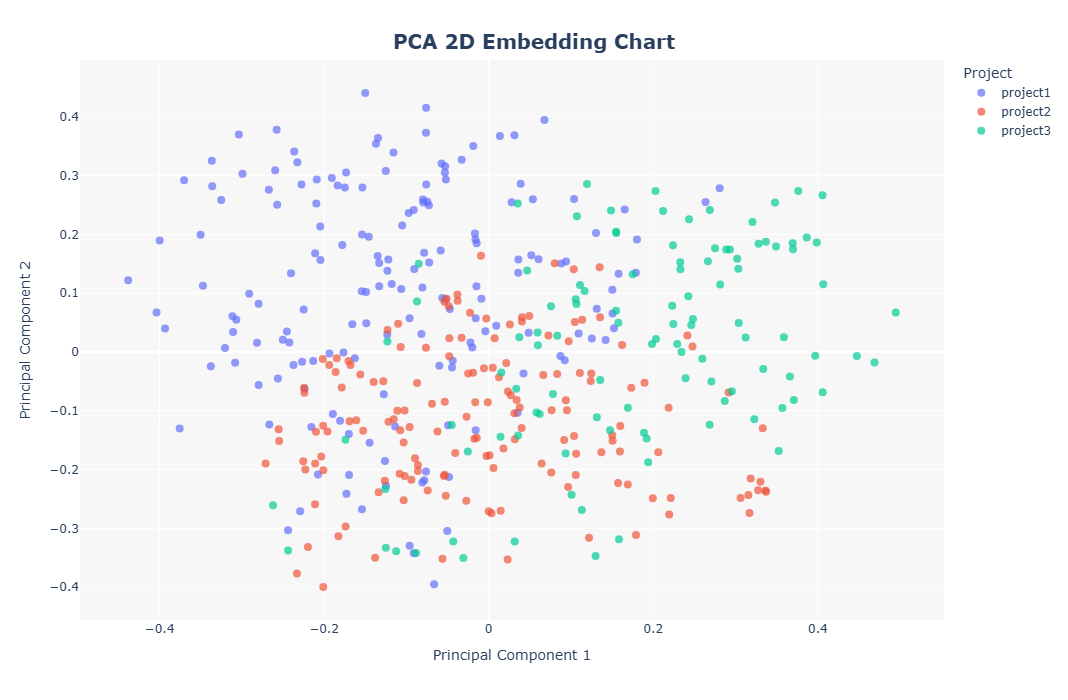

Explained variance PC1: 5.02%
Explained variance PC2: 4.76%
Cumulative explained variance: 9.78%


In [12]:
# PCA projection
pca = PCA(n_components=2, random_state=42)
reduced_vectors_pca = pca.fit_transform(vectors)

df_pca = pd.DataFrame({
    'PC1': reduced_vectors_pca[:, 0],
    'PC2': reduced_vectors_pca[:, 1],
    'Project': projects,
    'Type': doc_types,
    'Source': sources,
    'Headline': headlines,
    'Summary': [d[:80] for d in documents]
})

fig_pca = px.scatter(
    df_pca,
    x='PC1',
    y='PC2',
    color='Project',
    hover_data=['Project', 'Source', 'Type', 'Headline', 'Summary'],
    labels={'PC1': 'Principal Component 1', 'PC2': 'Principal Component 2'},
    height=700,
    width=1000
)

fig_pca.update_traces(marker=dict(size=8, opacity=0.7))
fig_pca.update_layout(
    font=dict(size=12),
    hovermode='closest',
    plot_bgcolor='rgba(240, 240, 240, 0.5)',
    title=dict(
        text='<b>PCA 2D Embedding Chart</b>', x=0.5, y=0.95,
        font=dict(size=20)
    ))
fig_pca.show()

print(f'Explained variance PC1: {pca.explained_variance_ratio_[0]:.2%}')
print(f'Explained variance PC2: {pca.explained_variance_ratio_[1]:.2%}')
print(f'Cumulative explained variance: {sum(pca.explained_variance_ratio_):.2%}')

### Visualization 2 — UMAP 2D

C:\Users\thoma\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


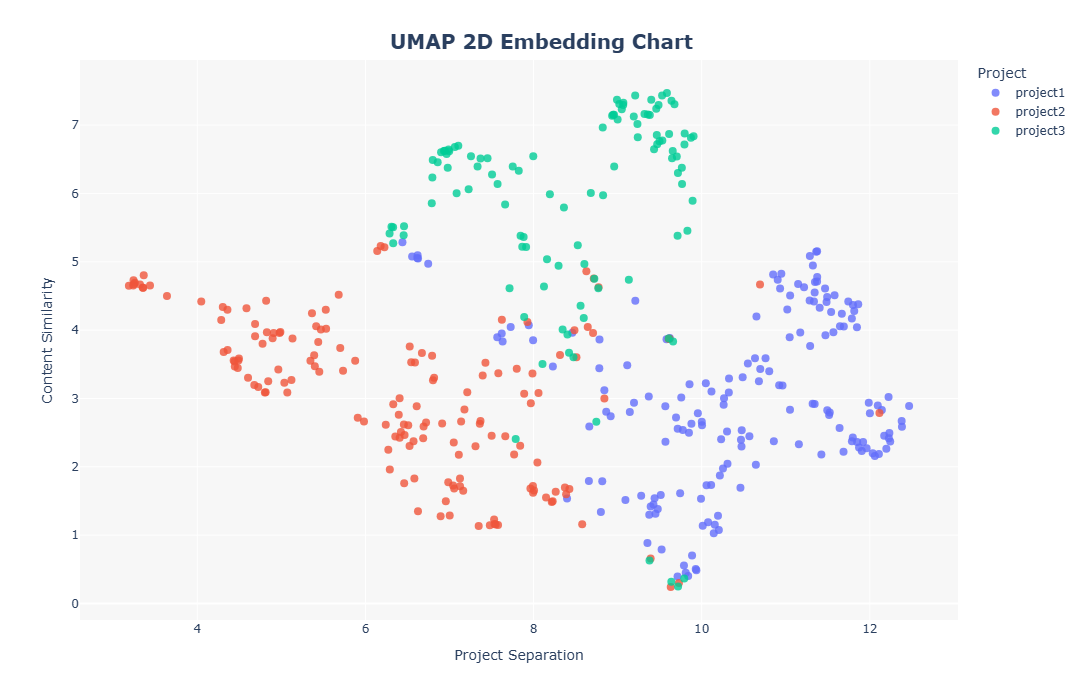

UMAP 2D chart saved


In [13]:
# UMAP projection
umap_model = umap.UMAP(
    n_components=2,
    min_dist=0.1,
    n_neighbors=15,
    random_state=42,
    metric='cosine'
)
reduced_vectors_umap = umap_model.fit_transform(vectors)

df_umap = pd.DataFrame({
    'UMAP 1': reduced_vectors_umap[:, 0],
    'UMAP 2': reduced_vectors_umap[:, 1],
    'Project': projects,
    'Type': doc_types,
    'Source': sources,
    'Headline': headlines,
    'Summary': [d[:80] for d in documents]
})

fig_umap = px.scatter(
    df_umap,
    x='UMAP 1',
    y='UMAP 2',
    color='Project',
    hover_data=['Project', 'Source', 'Type', 'Headline', 'Summary'],
    labels={'UMAP 1': 'Project Separation', 'UMAP 2': 'Content Similarity'},
    height=700,
    width=1000
)

fig_umap.update_traces(marker=dict(size=8, opacity=0.8))
fig_umap.update_layout(
    font=dict(size=12),
    hovermode='closest',
    plot_bgcolor='rgba(240, 240, 240, 0.5)',
    title=dict(
        text='<b>UMAP 2D Embedding Chart</b>', x=0.5, y=0.95,
        font=dict(size=20)
    ))

fig_umap.write_html(results_fig / 'umap_2d_chart.html')
fig_umap.write_image(results_fig / 'umap_2d_chart.png', width=1200, height=800, scale=2)
fig_umap.show()

print('UMAP 2D chart saved')

### Visualization 3 — UMAP 3D

C:\Users\thoma\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


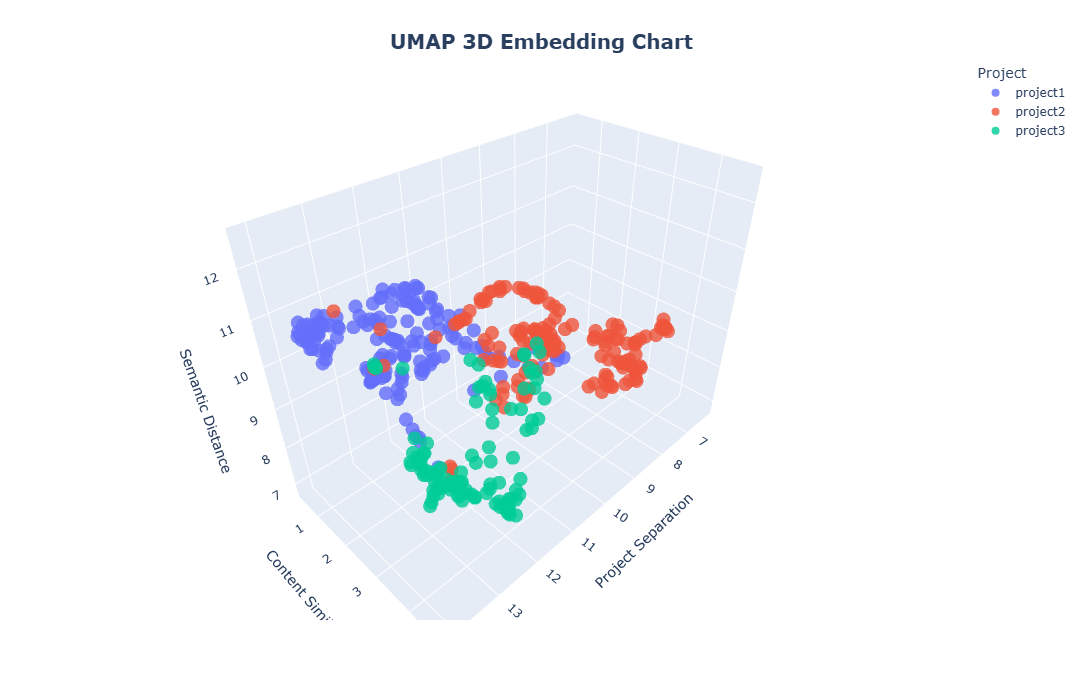

UMAP 3D chart saved


In [14]:
# UMAP projection
umap_model = umap.UMAP(
    n_components=3,
    min_dist=0.1,
    n_neighbors=15,
    random_state=42,
    metric='cosine'
)
reduced_vectors_umap = umap_model.fit_transform(vectors)

df_umap = pd.DataFrame({
    'UMAP 1': reduced_vectors_umap[:, 0],
    'UMAP 2': reduced_vectors_umap[:, 1],
    'UMAP 3': reduced_vectors_umap[:, 2],
    'Project': projects,
    'Type': doc_types,
    'Source': sources,
    'Headline': headlines,
    'Summary': [d[:80] for d in documents]
})

fig_umap = px.scatter_3d(
    df_umap,
    x='UMAP 1',
    y='UMAP 2',
    z='UMAP 3',
    color='Project',
    hover_data=['Project', 'Source', 'Type', 'Headline', 'Summary'],
    labels={'UMAP 1': 'Project Separation', 'UMAP 2': 'Content Similarity', 'UMAP 3': 'Semantic Distance'},
    height=700,
    width=1000
)

fig_umap.update_traces(marker=dict(size=8, opacity=0.8))
fig_umap.update_layout(
    font=dict(size=12),
    hovermode='closest',
    plot_bgcolor='rgba(240, 240, 240, 0.5)',
    title=dict(
        text='<b>UMAP 3D Embedding Chart</b>', x=0.5, y=0.95,
        font=dict(size=20)
    ))

fig_umap.write_html(results_fig / 'umap_3d_chart.html')
fig_umap.write_image(results_fig / 'umap_3d_chart.png', width=1200, height=800, scale=2)
fig_umap.show()

print('UMAP 3D chart saved')

---
## Key Takeaways

- Successfully processed all GitHub project files (text and images) using intelligent chunking and LLM-powered extraction
- Generated structured document chunks optimized for semantic retrieval; complex texts split into overlapping segments to preserve context
- Built ChromaDB knowledge base with **OpenAI text-embedding-3-small** vectors, enabling fast semantic search across all project documentation
- Visualized document embeddings via PCA (2D) and UMAP (2D/3D), revealing natural clustering by project type and content semantic similarity
- Memory efficiency: reduced 1536-dimensional embeddings to 2D/3D visualizations for human interpretation while preserving semantic relationships

The processed documents, flattened chunks, vectorized embeddings are ready for semantic search, cross-project knowledge retrieval, and intelligent question-answering workflows.